# Accessing the catalog

In this tutorial, we will:

- **open the alert archive** from the public URL or from USDF
- see which **columns** load by default, and choose others
- check how **up to date** the catalog is
- run a **cone search**, get one night's alerts, and plot one object's **light curve**

## Introduction

The alert archive has one row per alert Rubin has sent. A daily pipeline adds each night's alerts, so the catalog grows every day.

The same catalog is served in two places:

- **From anywhere:** `http://slac.data.lsdb.io:10942/lsdb/rubin_alert_archive/`
- **On USDF:** `/sdf/data/rubin/cosmicdata/lsdb/rubin_alert_archive`

Reading the files directly on USDF is faster, so use the path there.

> **Coming this week:** a margin catalog and a `diaSourceId` index. Until then, crossmatches can miss pairs that straddle a partition boundary, and looking up an alert by ID means scanning the whole catalog.

## 1. Install LSDB

```
pip install lsdb
```

This page was tested with LSDB 0.11. Older versions may work, but if something fails, upgrade first.

In [1]:
from pathlib import Path

import lsdb
import matplotlib.pyplot as plt

In [2]:
# Dask emits a lot of `INFO` logging. Raise the threshold to `WARNING`
# so the output stays readable
import logging

logging.getLogger().setLevel(logging.WARNING)
logging.getLogger("distributed").setLevel(logging.WARNING)

In [20]:
client.shutdown()

In [21]:
from dask.distributed import Client

client = Client(n_workers=4, threads_per_worker=1, memory_limit="8GB")

/sdf/group/rubin/sw/conda/envs/lsst-scipipe-13.0.0/lib/python3.13/site-packages/distributed/node.py:173: ResourceWarning: unclosed <socket.socket fd=210, family=2, type=1, proto=6, laddr=('0.0.0.0', 0)>
  if retries_left < 1:
/sdf/group/rubin/sw/conda/envs/lsst-scipipe-13.0.0/lib/python3.13/site-packages/distributed/node.py:188: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 13871 instead
  warnings.warn(


## 2. Open the catalog

In [6]:
PUBLIC_URL = "http://slac.data.lsdb.io:10942/lsdb/rubin_alert_archive/"
USDF_PATH = "/sdf/data/rubin/cosmicdata/lsdb/rubin_alert_archive"

# Use the files directly when we're on USDF, and the public URL everywhere else
catalog_path = USDF_PATH if Path(USDF_PATH).exists() else PUBLIC_URL

alerts = lsdb.open_catalog(catalog_path)
alerts

,ra,dec,diaSourceId,diaSource,diaObject,prvDiaForcedSources
npartitions=153,,,,,,
"Order: 0, Pixel: 4",double[pyarrow],double[pyarrow],int64[pyarrow],"nested<diaObjectId: [int64], ssObjectId: [int6...","nested<diaObjectId: [int64], nDiaSources: [int...","nested<diaForcedSourceId: [int64], visit: [int..."
...,...,...,...,...,...,...
"Order: 0, Pixel: 10",...,...,...,...,...,...
"Order: 0, Pixel: 11",...,...,...,...,...,...


Opening the catalog is lazy: it reads only the metadata. Nothing is loaded until you call `.compute()` (or `.head()`, a plot, and so on).

### 2.1 How up to date is it?

The catalog's metadata records how many alerts it holds and when it was last updated.

In [7]:
info = alerts.hc_structure.catalog_info
print(f"Alerts:       {info.total_rows:,}")
print(f"Last updated: {info.hats_creation_date}")

Alerts:       16,746,928
Last updated: 2026-11-02T23:49UTC


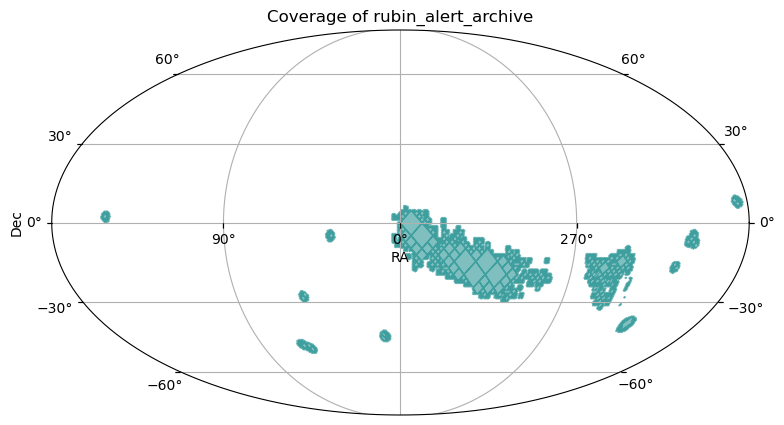

In [9]:
alerts.plot_coverage();

## 3. Choose columns

Each alert has four nested columns, and the first two always hold exactly one entry:

- `diaSource`: the detection that triggered the alert
- `diaObject`: the object it belongs to, as of the alert
- `prvDiaSources`: the object's earlier detections
- `prvDiaForcedSources`: forced photometry at the object's position

By default, LSDB loads a short list of the most useful fields:

In [14]:
list(alerts.columns)

['ra', 'dec', 'diaSourceId', 'diaSource', 'diaObject', 'prvDiaForcedSources']

In [16]:
# Everything available, including the fields not loaded by default
len(alerts.all_columns)

10

To load other fields, name them when opening the catalog. Use dot notation for fields inside a nested column. `ra` and `dec` are always loaded.

In [12]:
alerts_small = lsdb.open_catalog(
    catalog_path,
    columns=["diaSourceId", "diaSource.midpointMjdTai", "diaSource.band", "diaSource.psfFlux"],
)
alerts_small.columns

Index(['diaSourceId', 'ra', 'dec', 'diaSource'], dtype='str')

columns="all" loads everything, which is significantly more data than a few diaSource fields. Nearly all of it is the prvDiaSources and prvDiaForcedSources histories. Ask for only what you need.

## 4. Queries

### 4.1 Cone search

In [22]:
cone = alerts.cone_search(ra=63.2, dec=-47.8, radius_arcsec=60).compute()
cone.head()

Building task graph...


Computing Catalog:   0%|          | 0/1 [00:00<?, ?it/s]

ra        dec         diaSourceId  \
_healpix_29                                                     
2415470368755892541  63.181712 -47.791507  313761043575210076   
2415470016654305221  63.200428 -47.785327  313862204824748150   
2415470374491677374   63.18124 -47.791214  313862204958965762   
2415469990886397852   63.20168 -47.803595  313871015279067324   
2415470016311901697  63.200824 -47.785106  313871015410139251   

                                                             diaSource  \
_healpix_29                                                              
2415470368755892541  [{diaObjectId: 313761043575210076, ssObjectId:...   
2415470016654305221  [{diaObjectId: 313862204824748150, ssObjectId:...   
2415470374491677374  [{diaObjectId: 313862204958965762, ssObjectId:...   
2415469990886397852  [{diaObjectId: 313871015279067324, ssObjectId:...   
2415470016311901697  [{diaObjectId: 313871015410139251, ssObjectId:...   

                                                             diaObject  \
_healpix_29                                                              
2415470368755892541  [{diaObjectId: 313761043575210076, nDiaSources...   
2415470016654305221  [{diaObjectId: 313862204824748150, nDiaSources...   
2415470374491677374  [{diaObjectId: 313862204958965762, nDiaSources...   
2415469990886397852  [{diaObjectId: 313871015279067324, nDiaSources...   
2415470016311901697  [{diaObjectId: 313871015410139251, nDiaSources...   

                    prvDiaForcedSources  
_healpix_29                              
2415470368755892541                  []  
2415470016654305221                  []  
2415470374491677374                  []  
2415469990886397852                  []  
2415470016311901697                  []

### 4.2 One night's alerts

Filter on the detection time, `diaSource.midpointMjdTai`. Without a sky region this reads the whole catalog, so here we stay inside a one-degree cone. Drop the `cone_search` to get the whole night.

In [36]:
from astropy.time import Time, TimeDelta

night = Time("2026-02-24T00:00:00", scale="utc")
start, end = night.tai.mjd, (night + TimeDelta(1, format="jd")).tai.mjd

night_alerts = (
    lsdb.open_catalog(
        catalog_path,
        columns=["diaSourceId", "diaSource.midpointMjdTai", "diaSource.band"],
    )
    .cone_search(ra=63.2, dec=-47.8, radius_arcsec=3600)
    .query(f"diaSource.midpointMjdTai >= {start} and diaSource.midpointMjdTai < {end}")
    # A query on a nested field empties the non-matching diaSources but keeps
    # every row, so drop the emptied ones
    .map_partitions(lambda df: df.dropna(subset="diaSource"))
    .compute()
)
print(f"{len(night_alerts):,} alerts on {night.iso[:10]}")


Building task graph...


Computing Catalog:   0%|          | 0/11 [00:00<?, ?it/s]

186,598 alerts on 2026-02-24


LSDB may warn that the result could be over 1 GB. That estimate assumes every nested column is fully loaded, so it's too high when you select only a few fields, as here. Without `columns=`, the default columns include `prvDiaForcedSources` fields, and the same query really does take about 2.4 GB.

### 4.3 One object's light curve

Every detection of an object sends an alert, so an object's light curve is the `diaSource` of each of its alerts. Here we follow a supernova-like transient in the COSMOS field: we find its alerts with a small cone search around its position, then keep only the ones with its `diaObjectId`.

In [70]:
# A supernova-like transient in the COSMOS field
object_id = 170235219334922248
ra, dec = 148.474278, 1.718240

In [71]:
lc = (
    lsdb.open_catalog(
        catalog_path,
        columns=[
            "diaSource.diaObjectId",
            "diaSource.midpointMjdTai",
            "diaSource.band",
            "diaSource.psfFlux",
            "diaSource.psfFluxErr",
        ],
    )
    .cone_search(ra=ra, dec=dec, radius_arcsec=5)
    .query(f"diaSource.diaObjectId == {object_id}")
    .map_partitions(lambda df: df.dropna(subset="diaSource"))
    .compute()
)
print(f"{len(lc)} detections")

Building task graph...


Computing Catalog:   0%|          | 0/1 [00:00<?, ?it/s]

67 detections


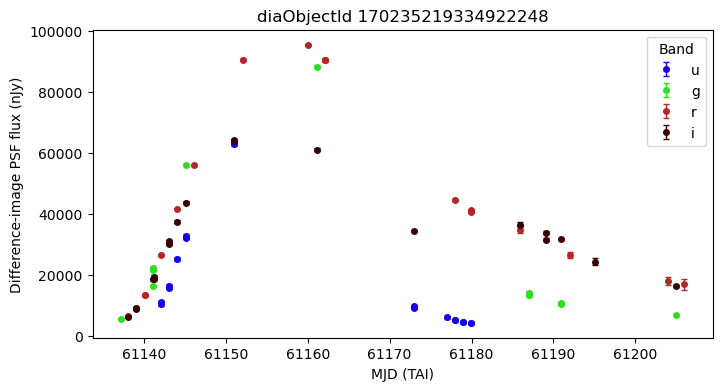

In [74]:
# Rubin's standard band colors
BAND_COLORS = {"u": "#1600EA", "g": "#31DE1F", "r": "#B52626", "i": "#370201", "z": "#BA52FF", "y": "#61A2B3"}

fig, ax = plt.subplots(figsize=(8, 4))
for band, color in BAND_COLORS.items():
    rows = lc[lc["diaSource.band"] == band]
    if len(rows):
        ax.errorbar(
            rows["diaSource.midpointMjdTai"],
            rows["diaSource.psfFlux"],
            yerr=rows["diaSource.psfFluxErr"],
            fmt="o",
            ms=4,
            capsize=2,
            elinewidth=1,
            color=color,
            label=band,
        )
ax.set_xlabel("MJD (TAI)")
ax.set_ylabel("Difference-image PSF flux (nJy)")
ax.set_title(f"diaObjectId {object_id}")
ax.legend(title="Band")
ax.ticklabel_format(axis="x", useOffset=False)
plt.show()

Don't build light curves from `prvDiaSources`: it repeats the object's earlier detections in every alert, and can miss detections from back-to-back visits. See [Things to know about the data](data_quirks.md).

## Close the Dask client

In [75]:
client.close()

## About

**Authors**: Olivia Lynn

**Last updated on**: Nov 3, 2026